In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_6036\4118401020.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x="Sector", y="Weight (%)", data=df, palette="viridis")


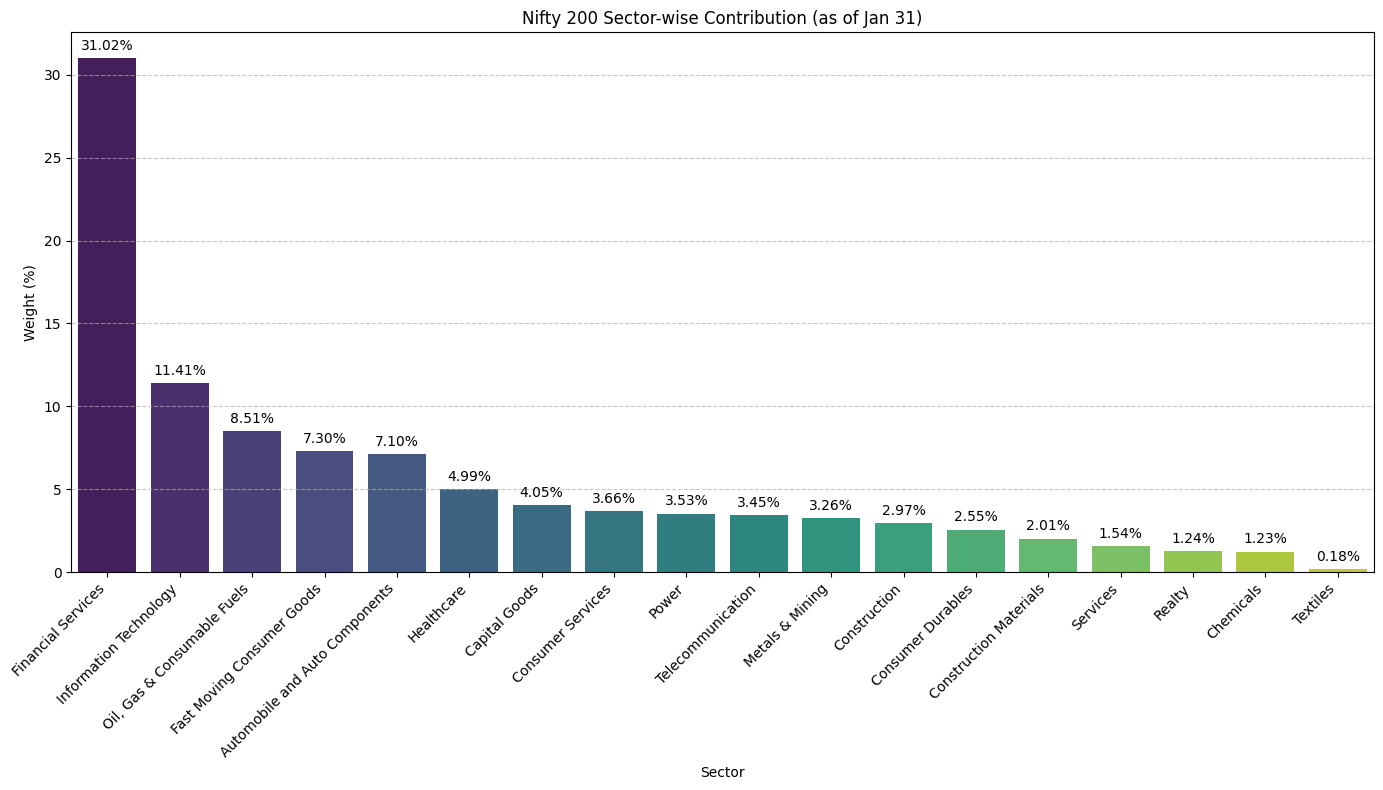

In [3]:
# Data
sectors = [
    "Financial Services", "Information Technology", "Oil, Gas & Consumable Fuels",
    "Fast Moving Consumer Goods", "Automobile and Auto Components", "Healthcare",
    "Capital Goods", "Consumer Services", "Power", "Telecommunication",
    "Metals & Mining", "Construction", "Consumer Durables", "Construction Materials",
    "Services", "Realty", "Chemicals", "Textiles"
]

weights = [31.02, 11.41, 8.51, 7.30, 7.10, 4.99, 4.05, 3.66, 3.53, 3.45,
           3.26, 2.97, 2.55, 2.01, 1.54, 1.24, 1.23, 0.18]

# Create DataFrame and reset index for proper enumeration later
df = pd.DataFrame({"Sector": sectors, "Weight (%)": weights})
df = df.sort_values(by="Weight (%)", ascending=False).reset_index(drop=True)

# Plot: vertical bar chart with a colorful palette
plt.figure(figsize=(14, 8))
ax = sns.barplot(x="Sector", y="Weight (%)", data=df, palette="viridis")

# Rotate x-axis labels for readability
plt.xticks(rotation=45, ha='right')

# Add weight labels on top of each bar
for i, weight in enumerate(df["Weight (%)"]):
    ax.text(i, weight + 0.5, f"{weight:.2f}%", color='black', ha="center", fontsize=10)

# Labels and title
plt.xlabel("Sector")
plt.ylabel("Weight (%)")
plt.title("Nifty 200 Sector-wise Contribution (as of Jan 31)")
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

In [6]:
nifty_df = pd.read_csv("ind_nifty200list.csv")
nifty_df.columns

Index(['Company Name', 'Industry', 'Symbol', 'Series', 'ISIN Code'], dtype='object')

In [8]:
# Group companies by industry and list the company names
industry_companies = nifty_df.groupby("Industry")["Company Name"].apply(list)

# Print companies for each industry
for industry, companies in industry_companies.items():
    print(f"Industry: {industry}")
    for company in companies:
        print(f"  - {company}")
    print()  # blank line for readability

Industry: Automobile and Auto Components
  - Apollo Tyres Ltd.
  - Bajaj Auto Ltd.
  - Balkrishna Industries Ltd.
  - Bharat Forge Ltd.
  - Bosch Ltd.
  - Eicher Motors Ltd.
  - Exide Industries Ltd.
  - Hero MotoCorp Ltd.
  - MRF Ltd.
  - Mahindra & Mahindra Ltd.
  - Maruti Suzuki India Ltd.
  - Samvardhana Motherson International Ltd.
  - Sona BLW Precision Forgings Ltd.
  - TVS Motor Company Ltd.
  - Tata Motors Ltd.
  - Tube Investments of India Ltd.

Industry: Capital Goods
  - ABB India Ltd.
  - APL Apollo Tubes Ltd.
  - Ashok Leyland Ltd.
  - Astral Ltd.
  - Bharat Dynamics Ltd.
  - Bharat Electronics Ltd.
  - Bharat Heavy Electricals Ltd.
  - CG Power and Industrial Solutions Ltd.
  - Cochin Shipyard Ltd.
  - Cummins India Ltd.
  - Escorts Kubota Ltd.
  - Hindustan Aeronautics Ltd.
  - Mazagoan Dock Shipbuilders Ltd.
  - Polycab India Ltd.
  - Siemens Ltd.
  - Supreme Industries Ltd.
  - Suzlon Energy Ltd.

Industry: Chemicals
  - Fertilisers and Chemicals Travancore Ltd.
  - P

In [27]:
# Load the data from the Excel file
df = pd.read_excel('finance.xlsx')

# Convert Market Cap to billions (if in T or B)
def convert_market_cap(value):
    if 'T' in str(value):
        return float(str(value).replace('T', '').strip()) * 1e3  # Convert trillion to billions
    elif 'B' in str(value):
        return float(str(value).replace('B', '').strip())  # Already in billions
    # Handle any other format if needed (e.g., M for millions)
    return float(str(value).replace(',', '').strip()) / 1e6 if isinstance(value, str) else value  # Convert to billions if it's in millions

df['Market Cap'] = df['Market Cap'].apply(convert_market_cap)

# Group by Industry and get top 5 based on Market Cap
top_5_per_industry = df.groupby('Industry').apply(lambda x: x.nlargest(5, 'Market Cap'))

# Reset the index to tidy the DataFrame
top_5_per_industry.reset_index(drop=True, inplace=True)

# Display the result
print(top_5_per_industry[['Name', 'Industry', 'Market Cap']])

                   Name                        Industry  Market Cap
0   Mahindra & Mahindra  Automobile and Auto Components     3160.00
1           Tata Motors  Automobile and Auto Components     2530.00
2            Bajaj Auto  Automobile and Auto Components     2380.00
3         Eicher Motors  Automobile and Auto Components     1300.00
4     TVS Motor Company  Automobile and Auto Components     1130.00
..                  ...                             ...         ...
79         Indus Towers               Telecommunication      896.53
80       Bharti Hexacom               Telecommunication      682.78
81        Vodafone Idea               Telecommunication      591.13
82  Tata Communications               Telecommunication      430.41
83      Page Industries                        Textiles      456.93

[84 rows x 3 columns]


In [28]:
top_5_per_industry.to_excel('top_5_industries.xlsx', index=False)